# Lab: Customer Clustering and High-Dimensional Data Visualization
**Topics:** K-Means, DBSCAN, PCA, t-SNE, evaluation, tuning, and alternatives  

## Learning outcomes
By completing this lab, you will be able to:
1. Explore and prepare customer/marketing data.
2. Explain why scaling matters for distance-based clustering.
3. Fit and interpret K-Means and DBSCAN.
4. Use the elbow method, silhouette score, and a k-distance plot.
5. Visualize data with PCA and t-SNE.
6. Compare algorithms and explain their limitations.

**Dataset:** We generate reproducible *simulated* customer data. It needs no download. It is not real customer data and must not be used to make real marketing decisions.

## 1. Import libraries

- **NumPy:** numerical arrays and random data.
- **pandas:** tables and summaries.
- **Matplotlib:** plots.
- **scikit-learn:** preprocessing, clustering, dimensionality reduction, and metrics.

If a package is missing, install it in your environment with `pip install package-name`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, DBSCAN, MiniBatchKMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Imports complete")

Imports complete


## 2. Create the simulated customer dataset

Each row is a customer. Features are illustrative:
- `Annual_Income`: annual income units
- `Spending_Score`: purchasing/spending score
- `Website_Visits`: visits during a period
- `Purchase_Frequency`: purchases during a period
- `Email_Engagement`: engagement score

We simulate four broad behavior profiles. The algorithms will receive only numeric features, not the profile names.

In [2]:
profile_centers = {
    "High value":      [90, 85, 8, 12, 85],
    "Budget focused":  [35, 30, 4, 4, 35],
    "Online browsers": [55, 35, 15, 3, 80],
    "Frequent buyers": [60, 75, 9, 15, 65],
}
noise = np.array([8, 10, 2, 2, 10])
rows, profile_reference = [], []

for name, center in profile_centers.items():
    samples = np.array(center) + np.random.normal(
        0, noise, size=(150, 5)
    )
    rows.extend(samples)
    profile_reference.extend([name] * len(samples))

feature_names = [
    "Annual_Income", "Spending_Score", "Website_Visits",
    "Purchase_Frequency", "Email_Engagement"
]
customers = pd.DataFrame(rows, columns=feature_names)
customers["Annual_Income"] = customers["Annual_Income"].clip(15, 150)
customers["Spending_Score"] = customers["Spending_Score"].clip(1, 100)
customers["Website_Visits"] = customers["Website_Visits"].clip(0, 30)
customers["Purchase_Frequency"] = customers["Purchase_Frequency"].clip(0, 25)
customers["Email_Engagement"] = customers["Email_Engagement"].clip(0, 100)
profile_reference = pd.Series(profile_reference, name="Simulated_Profile")

display(customers.head())
print("Shape:", customers.shape)

,Annual_Income,Spending_Score,Website_Visits,Purchase_Frequency,Email_Engagement
0,93.973713,83.617357,9.295377,15.046060,82.658466
1,88.126904,100.000000,9.534869,11.061051,90.425600
2,86.292658,80.342702,8.483925,8.173440,67.750822
3,85.501700,74.871689,8.628495,10.183952,70.876963
4,101.725190,82.742237,8.135056,9.150504,79.556173


Shape: (600, 5)


### Explore the table

Important pandas functions:
- `head(n=5)`: first rows.
- `shape`: row and column counts.
- `info()`: data types and non-missing counts.
- `describe()`: summary statistics.
- `isna().sum()`: missing-value count per column.
- `nunique()`: number of distinct values.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Annual_Income       600 non-null    float64
 1   Spending_Score      600 non-null    float64
 2   Website_Visits      600 non-null    float64
 3   Purchase_Frequency  600 non-null    float64
 4   Email_Engagement    600 non-null    float64
dtypes: float64(5)
memory usage: 23.6 KB


,Annual_Income,Spending_Score,Website_Visits,Purchase_Frequency,Email_Engagement
count,600.00,600.00,600.00,600.00,600.00
mean,60.29,56.21,9.00,8.54,67.14
std,20.94,26.22,4.33,5.43,20.81
min,15.00,1.04,0.00,0.00,13.47
25%,44.40,32.86,5.84,3.48,51.32
50%,57.74,54.54,8.37,8.27,71.84
75%,75.58,80.15,12.16,13.49,82.69
max,108.52,100.00,21.28,19.44,100.00


,Missing values
Annual_Income,0
Spending_Score,0
Website_Visits,0
Purchase_Frequency,0
Email_Engagement,0


,Distinct values
Annual_Income,600
Spending_Score,583
Website_Visits,600
Purchase_Frequency,587
Email_Engagement,586


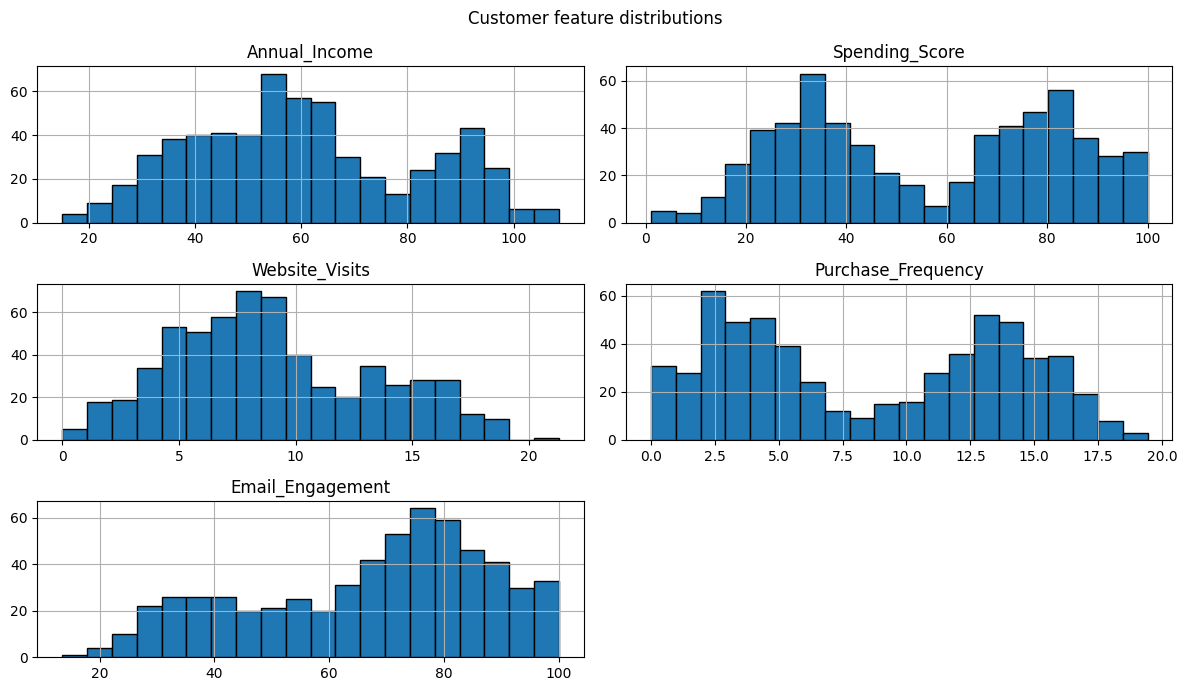

In [3]:
customers.info()
display(customers.describe().round(2))
display(customers.isna().sum().rename("Missing values"))
display(customers.nunique().rename("Distinct values"))

customers[feature_names].hist(figsize=(12, 7), bins=20, edgecolor="black")
plt.suptitle("Customer feature distributions")
plt.tight_layout()
plt.show()

## 3. Prepare and scale the data

Select numeric features only. Do not include IDs, labels, or the hidden simulated profile reference.

### Missing-value alternatives
- `dropna()`: remove incomplete rows; may waste data or bias results.
- `SimpleImputer(strategy="median")`: robust numeric baseline.
- `"mean"`: simple but affected by outliers.
- `"most_frequent"`: useful for categorical or discrete values.
- `KNNImputer`: estimates missing values from neighbors; more expensive and scale-sensitive.

This generated dataset has no missing values, but we demonstrate median imputation.

In [5]:
X = customers[feature_names].copy()

imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values after imputation:", X_imputed.isna().sum().sum())

Missing values after imputation: 0


### Why scale?

Distance-based methods can be dominated by features with large numeric ranges. `StandardScaler` centers each feature and scales it to unit standard deviation.

Popular choices:
- `StandardScaler()`: mean 0, standard deviation 1; common for K-Means/DBSCAN.
- `MinMaxScaler(feature_range=(0, 1))`: rescales to a range; sensitive to outliers.
- `RobustScaler(quantile_range=(25, 75))`: uses median and interquartile range; often useful with outliers.
- No scaling: only when units/ranges are already comparable or deliberately weighted.

Useful arguments:
- `StandardScaler(with_mean=True, with_std=True)`
- `MinMaxScaler(feature_range=(0, 1))`
- `RobustScaler(with_centering=True, with_scaling=True, quantile_range=(25.0, 75.0))`

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Original means:", X_imputed.mean().round(2).to_dict())
print("Scaled means:", np.round(X_scaled.mean(axis=0), 3))
print("Scaled standard deviations:", np.round(X_scaled.std(axis=0), 3))
print("Matrix shape:", X_scaled.shape)

Original means: {'Annual_Income': 60.29, 'Spending_Score': 56.21, 'Website_Visits': 9.0, 'Purchase_Frequency': 8.54, 'Email_Engagement': 67.14}
Scaled means: [ 0.  0.  0. -0. -0.]
Scaled standard deviations: [1. 1. 1. 1. 1.]
Matrix shape: (600, 5)


## 4. K-Means clustering

K-Means divides data into a chosen number, `K`, of clusters. It alternates between assigning points to the nearest centroid and updating each centroid to the mean of its assigned points.

It minimizes within-cluster squared distance:
\[
J = \sum_{i=1}^{n}\|x_i - \mu_{c_i}\|^2
\]

It works best for reasonably compact, roughly spherical clusters. It can be affected by outliers and the selected K.

### Important `KMeans` arguments

Common signature (defaults may differ by scikit-learn version):

`KMeans(n_clusters=8, init="k-means++", n_init="auto", max_iter=300, tol=1e-4, random_state=None, algorithm="lloyd")`

- `n_clusters`: number of clusters K.
- `init`: starting centroids; `"k-means++"` is common; `"random"` is an alternative.
- `n_init`: number of initializations. A numeric value like `10` works across many versions.
- `max_iter`: maximum iterations per initialization.
- `tol`: convergence tolerance.
- `random_state`: reproducibility.
- `algorithm`: `"lloyd"` is the standard choice; `"elkan"` can be faster in some cases but uses more memory.

Useful attributes: `cluster_centers_`, `labels_`, `inertia_`, `n_iter_`.  
Useful methods: `fit()`, `fit_predict()`, `predict(X_new)`, `transform()` (distances to each centroid).

### Choose K: elbow and silhouette

- **Inertia** is the sum of squared distances to assigned centroids. It decreases as K grows, so look for a bend/elbow.
- **Silhouette score** compares within-cluster closeness to nearest-other-cluster separation. Near +1 is usually good separation, near 0 indicates boundaries, and negative values may indicate poor assignments.
- Neither metric alone proves that a segmentation is useful to a business.

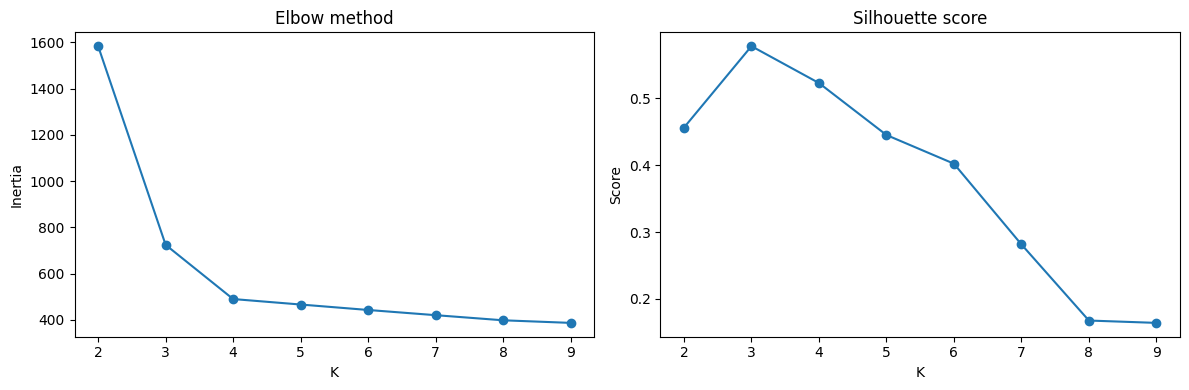

,K,Inertia,Silhouette
0,2,1583.683,0.456
1,3,724.327,0.578
2,4,489.979,0.523
3,5,466.289,0.445
4,6,442.697,0.402
5,7,420.229,0.282
6,8,398.091,0.168
7,9,386.868,0.164


In [7]:
k_values = range(2, 10)
inertias, silhouettes = [], []

for k in k_values:
    model = KMeans(
        n_clusters=k, init="k-means++", n_init=10,
        max_iter=300, random_state=RANDOM_STATE
    )
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="K", ylabel="Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set(title="Silhouette score", xlabel="K", ylabel="Score")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "K": list(k_values), "Inertia": inertias, "Silhouette": silhouettes
}).round(3))

**Checkpoint:** Why does inertia decrease when K increases? Would you always choose the K with the highest silhouette score? Explain.

Cluster counts:


,count
KMeans_Cluster,
0,153
1,150
2,150
3,147


Inertia: 489.98
Iterations: 4
Centroid shape: (4, 5)


,Annual_Income,Spending_Score,Website_Visits,Purchase_Frequency,Email_Engagement
KMeans_Cluster,,,,,
0,89.4,84.5,7.9,12.1,84.4
1,35.4,30.3,4.3,4.2,37.5
2,55.4,34.5,15.1,2.9,80.4
3,60.4,75.4,8.7,15.0,65.9


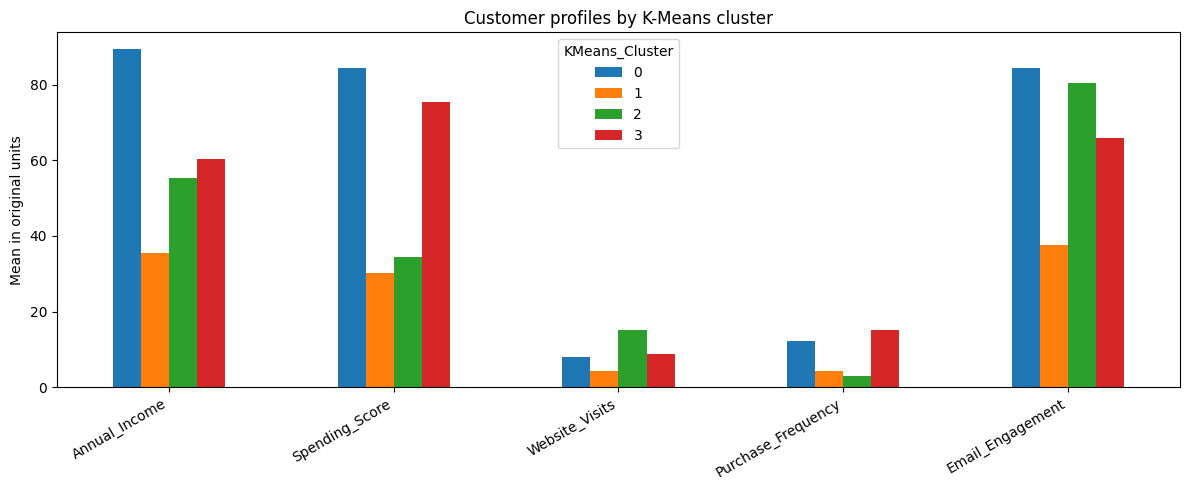

In [8]:
chosen_k = 4  # illustrative choice for this simulated dataset
kmeans = KMeans(
    n_clusters=chosen_k, init="k-means++", n_init=10,
    max_iter=300, random_state=RANDOM_STATE
)
customers["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
display(customers["KMeans_Cluster"].value_counts().sort_index())
print("Inertia:", round(kmeans.inertia_, 2))
print("Iterations:", kmeans.n_iter_)
print("Centroid shape:", kmeans.cluster_centers_.shape)

# Interpret clusters using original, understandable feature units.
profiles = customers.groupby("KMeans_Cluster")[feature_names].mean().round(1)
display(profiles)
profiles.T.plot(kind="bar", figsize=(12, 5))
plt.ylabel("Mean in original units")
plt.title("Customer profiles by K-Means cluster")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### K-Means variations and alternatives

- **MiniBatchKMeans:** faster for large datasets; important arguments include `batch_size`, `n_init`, `random_state`.
- **K-Medoids:** uses actual observations as representatives; available in extra packages such as `scikit-learn-extra`.
- **BisectingKMeans:** repeatedly splits clusters; available in recent scikit-learn versions.
- **AgglomerativeClustering:** hierarchical merging; useful when hierarchy matters.
- **GaussianMixture:** probabilistic memberships and elliptical components; not the same objective as K-Means.

MiniBatchKMeans example:

In [9]:
mini = MiniBatchKMeans(
    n_clusters=4, batch_size=100, n_init=10,
    random_state=RANDOM_STATE
)
mini_labels = mini.fit_predict(X_scaled)
print(pd.Series(mini_labels).value_counts().sort_index())

0    148
1    150
2    150
3    152
Name: count, dtype: int64


## 5. DBSCAN: density-based clustering

DBSCAN finds dense regions and labels points in sparse regions as noise.

- **Core point:** has at least `min_samples` points in its `eps` neighborhood; the point itself counts.
- **Border point:** near a core point but does not itself meet the core-point density requirement.
- **Noise:** not assigned to a density-connected cluster; scikit-learn labels it `-1`.

Unlike K-Means, DBSCAN does not require the number of clusters in advance and can detect non-spherical shapes. It can struggle when densities vary a lot.

### Important `DBSCAN` arguments

`DBSCAN(eps=0.5, min_samples=5, metric="euclidean", metric_params=None, algorithm="auto", leaf_size=30, p=None, n_jobs=None)`

- `eps`: neighborhood radius; **not** maximum cluster diameter.
- `min_samples`: density threshold for a core point, including itself.
- `metric`: `"euclidean"` is common; `"manhattan"` or `"cosine"` may suit some data.
- `metric_params`: extra metric settings when supported.
- `algorithm`: `"auto"`, `"ball_tree"`, `"kd_tree"`, `"brute"` where supported by the metric.
- `leaf_size`: affects tree-search speed/memory.
- `p`: Minkowski parameter; p=1 is Manhattan and p=2 is Euclidean.
- `n_jobs`: parallelism for neighbor search where supported.

Methods: `fit()`, `fit_predict()`. Attribute: `labels_`, with `-1` for noise.

In [10]:
dbscan = DBSCAN(
    eps=0.9, min_samples=8, metric="euclidean",
    algorithm="auto", n_jobs=-1
)
customers["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

display(customers["DBSCAN_Cluster"].value_counts().sort_index())
noise_count = (customers["DBSCAN_Cluster"] == -1).sum()
print(f"Noise: {noise_count} ({noise_count / len(customers):.1%})")
print("Clusters excluding noise:",
      len(set(customers["DBSCAN_Cluster"]) - {-1}))

,count
DBSCAN_Cluster,
-1,6
0,298
1,148
2,148


Noise: 6 (1.0%)
Clusters excluding noise: 3


### Visualize DBSCAN on two original features

DBSCAN was fitted using all five scaled features. This plot displays only two original features, so it may not perfectly reflect the full-dimensional structure.

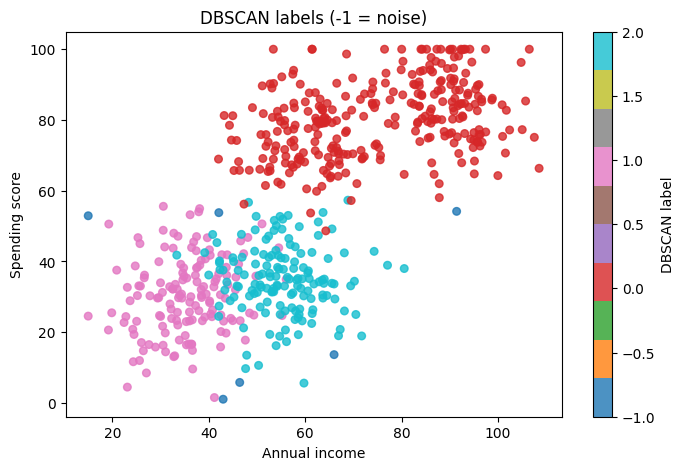

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(
    customers["Annual_Income"], customers["Spending_Score"],
    c=customers["DBSCAN_Cluster"], cmap="tab10", s=30, alpha=0.8
)
plt.xlabel("Annual income")
plt.ylabel("Spending score")
plt.title("DBSCAN labels (-1 = noise)")
plt.colorbar(label="DBSCAN label")
plt.show()

### Tune DBSCAN with a k-distance plot

If `eps` is too small, many points may be noise. If too large, separate groups may merge. Increasing `min_samples` makes the core-point density requirement stricter.

A k-distance plot sorts each point's distance to its k-th nearest neighbor. A bend can suggest an `eps` range, but it is not a guaranteed answer.

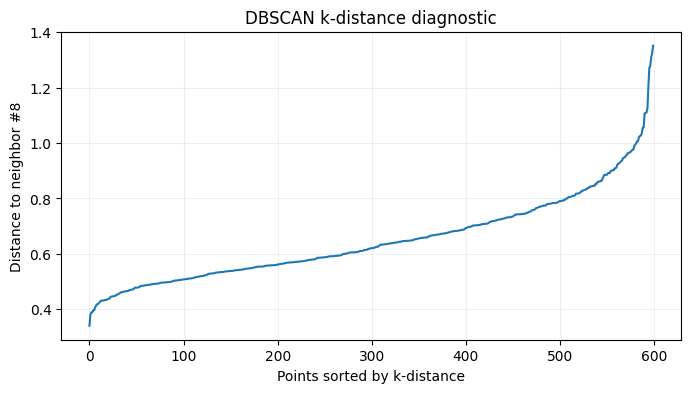

In [12]:
k = 8  # often begin by matching min_samples
nn = NearestNeighbors(n_neighbors=k, metric="euclidean", n_jobs=-1)
nn.fit(X_scaled)
distances, indices = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Points sorted by k-distance")
plt.ylabel(f"Distance to neighbor #{k}")
plt.title("DBSCAN k-distance diagnostic")
plt.grid(alpha=0.2)
plt.show()

In [13]:
results = []
for eps in [0.5, 0.7, 0.9, 1.1, 1.3]:
    for min_samples in [5, 8, 12]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        non_noise = labels != -1
        n_clusters = len(set(labels[non_noise]))
        sil = np.nan
        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters_excluding_noise": n_clusters,
            "noise_percent": round(100 * np.mean(labels == -1), 1),
            "silhouette_non_noise": sil
        })
display(pd.DataFrame(results).round(3))

,eps,min_samples,clusters_excluding_noise,noise_percent,silhouette_non_noise
0,0.5,5,4,39.3,0.584
1,0.5,8,7,57.3,0.297
2,0.5,12,4,79.2,0.673
3,0.7,5,3,5.3,0.590
4,0.7,8,3,7.8,0.596
5,0.7,12,3,9.8,0.600
6,0.9,5,3,0.8,0.581
7,0.9,8,3,1.0,0.581
8,0.9,12,3,1.0,0.581
9,1.1,5,2,0.2,0.457


### DBSCAN alternatives

- **OPTICS:** explores clustering structure across a range of radii; useful when densities vary. Common arguments include `min_samples`, `max_eps`, `metric`, `cluster_method`, `xi`, `min_cluster_size`.
- **HDBSCAN:** hierarchical density-based clustering, often useful for varying densities; available in recent scikit-learn versions and the separate `hdbscan` package. Check your version/API.
- **MeanShift:** estimates dense regions without specifying K, but may be expensive.
- **SpectralClustering:** can capture some non-convex structures, but requires a cluster count and may be costly.

Try OPTICS if DBSCAN is highly sensitive to a single `eps` value.

## 6. Compare K-Means and DBSCAN

Silhouette scores should be handled carefully:
- K-Means assigns every observation to a cluster.
- DBSCAN may label points as noise.
- For DBSCAN below, the silhouette score is calculated only on non-noise points, and the noise percentage is reported separately.
- This score covers a subset of the data, so compare it cautiously with K-Means' score on all points.

Other metrics:
- `davies_bouldin_score`: lower is generally better.
- `calinski_harabasz_score`: higher often indicates compact, separated clusters.
None proves business usefulness.

In [ ]:
km_labels = customers["KMeans_Cluster"].to_numpy()
db_labels = customers["DBSCAN_Cluster"].to_numpy()
non_noise = db_labels != -1
db_cluster_count = len(set(db_labels[non_noise]))

db_sil = np.nan
db_db = np.nan
db_ch = np.nan
if db_cluster_count >= 2 and non_noise.sum() > db_cluster_count:
    db_sil = silhouette_score(X_scaled[non_noise], db_labels[non_noise])
    db_db = davies_bouldin_score(X_scaled[non_noise], db_labels[non_noise])
    db_ch = calinski_harabasz_score(X_scaled[non_noise], db_labels[non_noise])

comparison = pd.DataFrame([
    {
        "Method": "K-Means",
        "Clusters": len(set(km_labels)),
        "Noise %": 0,
        "Silhouette": silhouette_score(X_scaled, km_labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, km_labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, km_labels)
    },
    {
        "Method": "DBSCAN",
        "Clusters": db_cluster_count,
        "Noise %": 100 * np.mean(db_labels == -1),
        "Silhouette (non-noise)": db_sil,
        "Davies-Bouldin (non-noise)": db_db,
        "Calinski-Harabasz (non-noise)": db_ch
    }
])
display(comparison.round(3))

## 7. PCA: principal component analysis

PCA creates new **linear combinations** of original features. The first principal component captures the greatest possible variance along a linear direction; later components capture remaining variance under orthogonality constraints.

Uses: visualization, compression, reducing correlated features, and preprocessing.

### Important `PCA` arguments
`PCA(n_components=None, copy=True, whiten=False, svd_solver="auto", tol=0.0, iterated_power="auto", random_state=None)`

- `n_components`: number of components, or a variance fraction in supported solver modes.
- `copy`: whether to preserve input during fitting.
- `whiten`: rescales components to unit variance; may help some models but removes relative variance scales.
- `svd_solver`: `"auto"`, `"full"`, `"arpack"`, `"randomized"` depending on version and input.
- `random_state`: used by randomized solvers.
- `explained_variance_ratio_`: variance fraction per component.
- `components_`: component directions/loadings.
- `fit_transform(X)`: fit and project.
- `inverse_transform(Z)`: reconstruct an approximation.

For large datasets, `IncrementalPCA` supports batch-wise fitting.

In [ ]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

display(pd.DataFrame({
    "Component": np.arange(1, len(explained) + 1),
    "Variance explained": explained,
    "Cumulative variance": cumulative
}).round(3))

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(explained) + 1), cumulative, marker="o")
plt.axhline(0.90, linestyle="--", label="90% reference")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.xticks(np.arange(1, len(explained) + 1))
plt.grid(alpha=0.2)
plt.legend()
plt.show()

In [ ]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca_2d.shape)
print("Variance retained by 2 PCs:",
      f"{pca_2d.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
                c=customers["KMeans_Cluster"], cmap="viridis", s=25)
axes[0].set(title="PCA colored by K-Means", xlabel="PC1", ylabel="PC2")
axes[1].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
                c=customers["DBSCAN_Cluster"], cmap="tab10", s=25)
axes[1].set(title="PCA colored by DBSCAN", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()

## 8. t-SNE: nonlinear visualization

t-SNE (t-distributed Stochastic Neighbor Embedding) tries to preserve local neighborhood similarities in a low-dimensional map.

Unlike PCA:
- axes do not represent variance directions;
- global distances between groups can be misleading;
- cluster sizes and gaps should not be interpreted literally;
- results may change with settings and initialization.

### Important `TSNE` arguments (check version)
`TSNE(n_components=2, perplexity=30.0, early_exaggeration=12.0, learning_rate="auto", max_iter=1000, metric="euclidean", init="pca", random_state=None, method="barnes_hut", angle=0.5)`

- `n_components`: output dimensions, usually 2 or 3 for visualization.
- `perplexity`: effective neighborhood scale; must be smaller than sample count. Try values such as 5, 15, 30, or 50 when suitable.
- `early_exaggeration`: influences early separation.
- `learning_rate`: `"auto"` or a numeric value.
- `max_iter`: iterations; older versions may call this `n_iter`.
- `metric`: distance in original space.
- `init`: `"pca"` or `"random"` in common versions.
- `random_state`: reproducibility.
- `method`: `"barnes_hut"` is faster for common 2D/3D cases; `"exact"` can be slower.
- `angle`: speed/accuracy tradeoff for Barnes-Hut.

Standard scikit-learn t-SNE does not provide the general-purpose `transform()` for new samples that PCA provides. Use t-SNE mainly for exploration.

In [ ]:
tsne = TSNE(
    n_components=2, perplexity=30,
    early_exaggeration=12.0, learning_rate="auto",
    max_iter=1000, metric="euclidean", init="pca",
    random_state=RANDOM_STATE, method="barnes_hut", angle=0.5
)
X_tsne = tsne.fit_transform(X_scaled)
print("Original shape:", X_scaled.shape)
print("t-SNE shape:", X_tsne.shape)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1],
                c=customers["KMeans_Cluster"], cmap="viridis", s=25)
axes[0].set(title="t-SNE colored by K-Means",
            xlabel="t-SNE dimension 1", ylabel="t-SNE dimension 2")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                c=customers["DBSCAN_Cluster"], cmap="tab10", s=25)
axes[1].set(title="t-SNE colored by DBSCAN",
            xlabel="t-SNE dimension 1", ylabel="t-SNE dimension 2")
plt.tight_layout()
plt.show()

### Perplexity experiment

Perplexity is related to the effective number of neighbors, not simply a fixed nearest-neighbor count. Compare multiple values; no single plot proves that clusters are real. Larger datasets may require more careful tuning.

In [ ]:
perplexities = [5, 15, 30, 50]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))

for ax, perp in zip(axes, perplexities):
    embedding = TSNE(
        n_components=2, perplexity=perp, init="pca",
        learning_rate="auto", max_iter=750,
        random_state=RANDOM_STATE
    ).fit_transform(X_scaled)
    ax.scatter(embedding[:, 0], embedding[:, 1],
               c=customers["KMeans_Cluster"], cmap="viridis", s=10)
    ax.set_title(f"Perplexity={perp}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("t-SNE sensitivity to perplexity")
plt.tight_layout()
plt.show()

## 9. PCA vs t-SNE

| Property | PCA | t-SNE |
|---|---|---|
| Type | Linear | Nonlinear |
| Main emphasis | Maximum variance directions | Local neighborhood similarity |
| Explained variance ratio | Available | Not available |
| Axes interpretable as combinations of original features | Yes | No |
| Transform new samples using fitted model | Yes | Not in standard scikit-learn t-SNE |
| Common purpose | Compression, preprocessing, visualization | Exploratory 2D/3D visualization |

If a group appears in a plot, inspect original feature profiles and validate stability before concluding it is a meaningful segment.

## 10. Popular clustering alternatives

### Agglomerative hierarchical clustering
Starts with individual points and repeatedly merges groups.

Important arguments:
- `n_clusters`: desired number of clusters.
- `linkage`: `"ward"`, `"complete"`, `"average"`, or `"single"`.
- `metric`: distance measure; Ward requires Euclidean distance.
- `distance_threshold`: can stop merging at a distance threshold in supported versions; typically set `n_clusters=None` when using it.

### Gaussian Mixture Model (GMM)
Models data as a mixture of Gaussian distributions and can return membership probabilities.

Important arguments:
- `n_components`: number of mixture components.
- `covariance_type`: `"full"`, `"tied"`, `"diag"`, `"spherical"`.
- `reg_covar`: covariance regularization.
- `n_init`, `random_state`: initialization and reproducibility.

Methods: `fit_predict()`, `predict_proba()`, `aic()`, `bic()`. Lower AIC/BIC is preferred when comparing candidates fitted to the same data.

Other methods:
- `MiniBatchKMeans`: large datasets.
- `OPTICS` / `HDBSCAN`: varying-density clusters.
- `SpectralClustering`: some non-convex structures, often more costly.
- `MeanShift`: dense regions without a predefined K, potentially expensive.

In [ ]:
agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)
print("Agglomerative counts:")
display(pd.Series(agg_labels).value_counts().sort_index())

gmm = GaussianMixture(
    n_components=4, covariance_type="full",
    reg_covar=1e-6, n_init=3, random_state=RANDOM_STATE
)
gmm_labels = gmm.fit_predict(X_scaled)
gmm_probs = gmm.predict_proba(X_scaled)

print("GMM counts:")
display(pd.Series(gmm_labels).value_counts().sort_index())
print("First five membership-probability rows:")
display(pd.DataFrame(gmm_probs[:5]).round(3))
print("GMM AIC:", round(gmm.aic(X_scaled), 1))
print("GMM BIC:", round(gmm.bic(X_scaled), 1))

## 11. Optional check: compare against the simulated reference

The generated profile names are available only because this is a teaching dataset. In a real unsupervised problem, these labels are usually unknown. Do **not** include them as input features.

In [ ]:
display(pd.crosstab(
    profile_reference, customers["KMeans_Cluster"], normalize="index"
).round(2))

display(pd.crosstab(
    profile_reference, customers["DBSCAN_Cluster"], normalize="index"
).round(2))

## 12. Student exercises

1. Fit K-Means with K=3, 4, and 5. Compare inertia, silhouette, and cluster profiles.
2. Try at least three DBSCAN `eps` values and three `min_samples` values. Record cluster counts and noise percentage.
3. Fit K-Means once on unscaled `X` and once on `X_scaled`. Explain any differences.
4. Compare PCA and t-SNE visualizations. What does each method try to preserve?
5. Change t-SNE perplexity and explain how the map changes.
6. Recommend a method to a marketing team. Discuss cluster interpretability, stability, and ethical use.
7. Explain why the simulated data should not be used for real campaign decisions.

## 13. Viva questions with answer guide

1. **Is clustering supervised?** Usually no; it does not require target labels.
2. **Why scale?** Distance calculations depend on feature ranges.
3. **What is inertia?** Sum of squared distances to assigned K-Means centroids.
4. **Why does inertia decrease as K grows?** More centroids allow closer assignments.
5. **What does DBSCAN label -1 mean?** Noise.
6. **eps vs min_samples?** Neighborhood radius vs density threshold for a core point.
7. **What does PCA optimize?** Variance captured along orthogonal linear directions.
8. **What does t-SNE preserve?** Local neighborhood similarities.
9. **Can t-SNE cluster distances be interpreted literally?** Generally no.
10. **Does a high silhouette prove business value?** No; validate with profiles, stability, and domain knowledge.

## 14. Final checklist

- [ ] Explain every feature and why it was selected.
- [ ] Explain why and how the data was scaled.
- [ ] Interpret elbow and silhouette plots.
- [ ] Explain K-Means centroids in original units.
- [ ] Explain DBSCAN `eps`, `min_samples`, core/border/noise points.
- [ ] Compare PCA and t-SNE without over-interpreting plots.
- [ ] Name at least two clustering alternatives.
- [ ] State limitations and ethical considerations.

**Takeaway:** Clustering proposes groups; visualization helps explore them; domain validation determines whether the groups are useful.